In [ ]:

# ATIVIDADE PRÁTICA 3 — GARIMPO E DIAGNÓSTICO DE DADOS
# Dataset: SINAN / Dengue 2026
# Aluna: Nathalia Paes

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

import requests

url = "https://apidadosabertos.saude.gov.br/arboviroses/dengue?limit=1000&offset=0"

response = requests.get(url)

dados = response.json()

df = pd.json_normalize(dados['parametros'])
print("Quantidade de linhas e colunas:")
print(df.shape)
print("\nInformações gerais da base:")
df.info()
df.head()
df.dtypes
df.columns
nulos = (
    df.isnull().sum() / len(df)
) * 100

nulos = nulos.reset_index()

nulos.columns = [
    'Coluna',
    'Percentual de Valores Nulos'
]

nulos = nulos.sort_values(
    by='Percentual de Valores Nulos',
    ascending=False
)

print("\nTop 10 colunas com mais valores ausentes:")
nulos.head(10)

duplicados = df.duplicated().sum()

print(f"\nQuantidade de registros duplicados: {duplicados}")



Quantidade de linhas e colunas:
(20, 197)

Informações gerais da base:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Columns: 197 entries, tp_not to in_aids
dtypes: object(197)
memory usage: 30.9+ KB

Top 10 colunas com mais valores ausentes:

Quantidade de registros duplicados: 0


In [ ]:
print(df.columns.tolist())

['tp_not', 'id_agravo', 'dt_notific', 'sem_not', 'nu_ano', 'sg_uf_not', 'id_municip', 'id_regiona', 'id_unidade', 'dt_sin_pri', 'sem_pri', 'nu_idade_n', 'cs_sexo', 'cs_gestant', 'cs_raca', 'cs_escol_n', 'sg_uf', 'id_mn_resi', 'id_rg_resi', 'id_pais', 'nduplic_n', 'dt_digita', 'cs_flxret', 'flxrecebi', 'migrado_w', 'dt_invest', 'id_ocupa_n', 'dt_soro', 'resul_soro', 'histopa_n', 'dt_viral', 'resul_vi_n', 'sorotipo', 'imunoh_n', 'dt_pcr', 'resul_pcr_', 'classi_fin', 'criterio', 'tpautocto', 'coufinf', 'copaisinf', 'comuninf', 'doenca_tra', 'evolucao', 'dt_obito', 'dt_encerra', 'mani_hemor', 'epistaxe', 'gengivo', 'metro', 'petequias', 'hematura', 'sangram', 'laco_n', 'plasmatico', 'evidencia', 'plaq_menor', 'con_fhd', 'complica', 'hospitaliz', 'dt_interna', 'uf', 'municipio', 'arquivo', 'ano_nasc', 'febre', 'mialgia', 'cefaleia', 'exantema', 'vomito', 'nausea', 'dor_costas', 'conjuntvit', 'artrite', 'artralgia', 'petequia_n', 'leucopenia', 'laco', 'dor_retro', 'diabetes', 'hematolog', 'h


Distribuição dos casos por sexo:
       Sexo  Quantidade de Casos
0  Mulheres                   10
1    Homens                   10


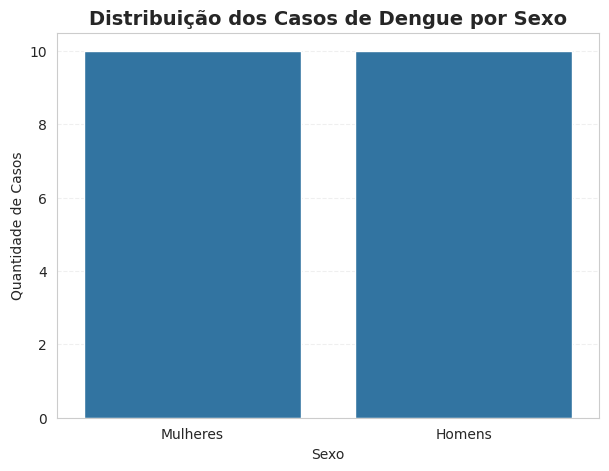

In [ ]:
df['cs_sexo'] = df['cs_sexo'].replace({
    'M': 'Homens',
    'F': 'Mulheres',
    'I': 'Ignorado'
})

df_sexo = df[df['cs_sexo'] != 'Ignorado']

sexo = df_sexo['cs_sexo'].value_counts().reset_index()

sexo.columns = [
    'Sexo',
    'Quantidade de Casos'
]

print("\nDistribuição dos casos por sexo:")
print(sexo)

plt.figure(figsize=(7,5))

sns.barplot(
    x='Sexo',
    y='Quantidade de Casos',
    data=sexo
)

plt.title(
    'Distribuição dos Casos de Dengue por Sexo',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Sexo')

plt.ylabel('Quantidade de Casos')

plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.show()

A base de dados do SINAN/Dengue apresenta uma estrutura rica em informações epidemiológicas, sendo adequada para análises exploratórias em saúde pública.

Durante a exploração dos dados, foram identificados:

* valores ausentes em diversas colunas;
* necessidade de tradução de códigos;
* registros duplicados;
* inconsistências em alguns campos.

Também foi realizado o tratamento da variável de sexo, removendo registros ignorados para melhorar a qualidade da análise visual.

Dessa forma, conclui-se que a base necessita de limpeza e padronização antes de análises estatísticas mais avançadas.
